In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the cleaned Excel workbook
file_path = "GeoB1515_XRD.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="Analysis_Data"
)


In [24]:
carbonate_columns = [
    "Calcite_pct",
    "Mg_rich_Calcite_pct",
    "Aragonite_pct",
    "Ankerite_Dolomite_pct",
    "Siderite_Magnesite_pct"
]

carbonate_data = df[
    ["Sample_ID", "Depth_cm"] + carbonate_columns
]

In [25]:
# Check whether the two depth columns are identical
(df["Depth_cm"] == df["Depth sed [cm]"]).all()

np.True_

## carbonate data analysis

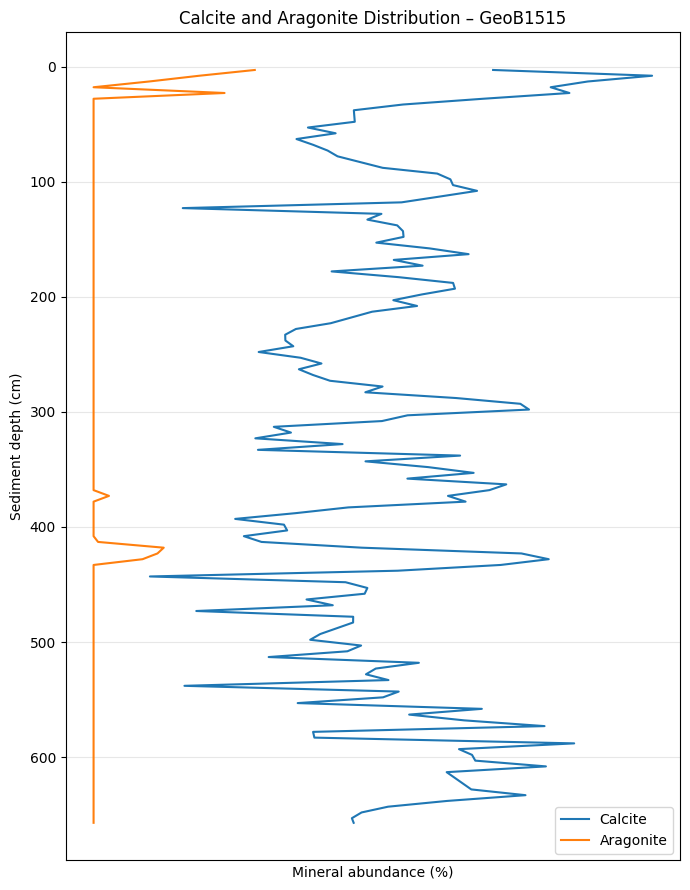

In [56]:
import matplotlib.pyplot as plt

# Sort samples by depth
carbonate_data = carbonate_data.sort_values("Depth_cm")

# Create the plot
fig, ax = plt.subplots(figsize=(7, 9))

ax.plot(
    carbonate_data["Calcite_pct"],
    carbonate_data["Depth_cm"],
    label="Calcite",
    linewidth=1.5
)

ax.plot(
    carbonate_data["Aragonite_pct"],
    carbonate_data["Depth_cm"],
    label="Aragonite",
    linewidth=1.5
)

# Sediment depth increases downward
ax.invert_yaxis()

ax.set_xlabel("Mineral abundance (%)")
ax.set_ylabel("Sediment depth (cm)")
ax.set_title("Calcite and Aragonite Distribution – GeoB1515")
ax.legend()
ax.grid(True, alpha=0.3)

ax.set_xticks([])

plt.tight_layout()
plt.show()

## Aragonite v Calcite Analysis

In [26]:
# Identify samples with measurable aragonite
aragonite_samples = carbonate_data[
    carbonate_data["Aragonite_pct"] > 0
][[
    "Sample_ID",
    "Depth_cm",
    "Calcite_pct",
    "Aragonite_pct"
]]

## Silicate Analysis

In [27]:
df["Major_Silicate_Sum_pct"] = (
    df["Quartz_pct"]
    + df["Plagioclase_pct"]
    + df["K_Feldspar_pct"]
    + df["Phyllosilicate_pct"]
)

comparison = df[[
    "Depth_cm",
    "Reported_Carbonate_Sum_pct",
    "Major_Silicate_Sum_pct"
]]

In [28]:
# Calculate the correlation between the two mineral groups
correlation = df[
    ["Reported_Carbonate_Sum_pct", "Major_Silicate_Sum_pct"]
].corr()

correlation

,Reported_Carbonate_Sum_pct,Major_Silicate_Sum_pct
Reported_Carbonate_Sum_pct,1.00000,-0.93239
Major_Silicate_Sum_pct,-0.93239,1.00000


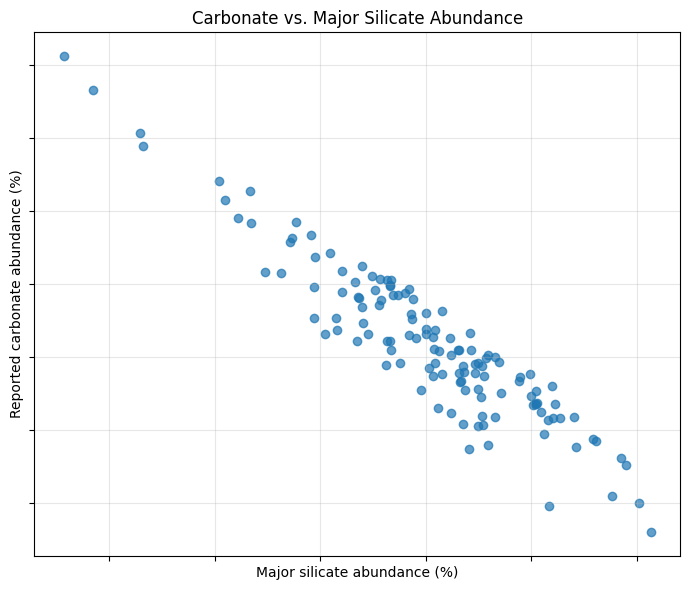

In [32]:
plt.figure(figsize=(7, 6))

plt.scatter(
    df["Major_Silicate_Sum_pct"],
    df["Reported_Carbonate_Sum_pct"],
    alpha=0.7
)

plt.xlabel("Major silicate abundance (%)")
plt.ylabel("Reported carbonate abundance (%)")
plt.title("Carbonate vs. Major Silicate Abundance")

plt.grid(True, alpha=0.3)

plt.tick_params(axis="both", labelbottom=False, labelleft=False)

plt.tight_layout()
plt.show()

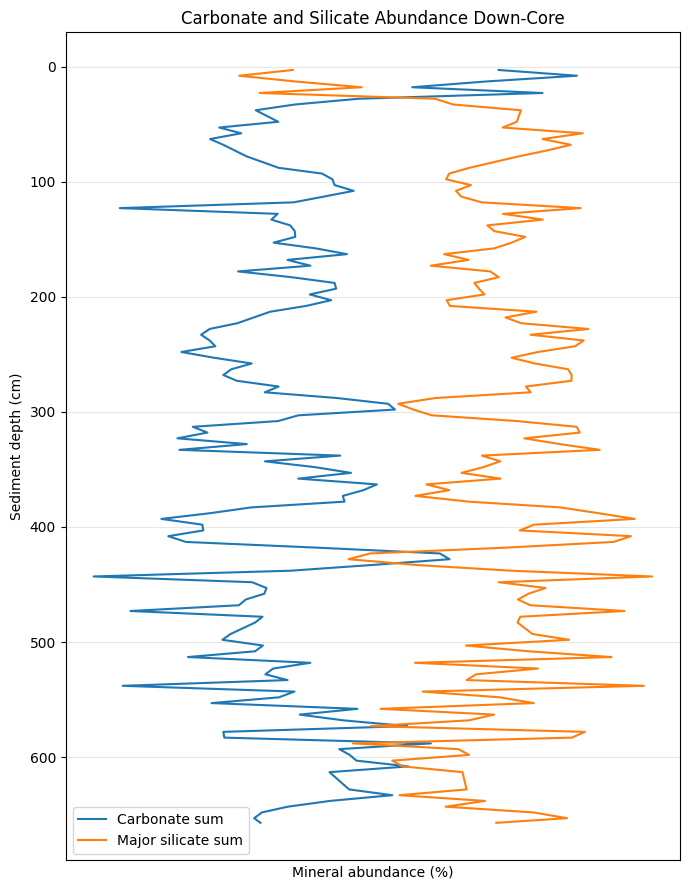

In [33]:
fig, ax = plt.subplots(figsize=(7, 9))

ax.plot(
    df["Reported_Carbonate_Sum_pct"],
    df["Depth_cm"],
    label="Carbonate sum",
    linewidth=1.5
)

ax.plot(
    df["Major_Silicate_Sum_pct"],
    df["Depth_cm"],
    label="Major silicate sum",
    linewidth=1.5
)

ax.invert_yaxis()

ax.set_xlabel("Mineral abundance (%)")
ax.set_ylabel("Sediment depth (cm)")
ax.set_title("Carbonate and Silicate Abundance Down-Core")

ax.legend()
ax.grid(True, alpha=0.3)

ax.set_xticks([])

plt.tight_layout()
plt.show()

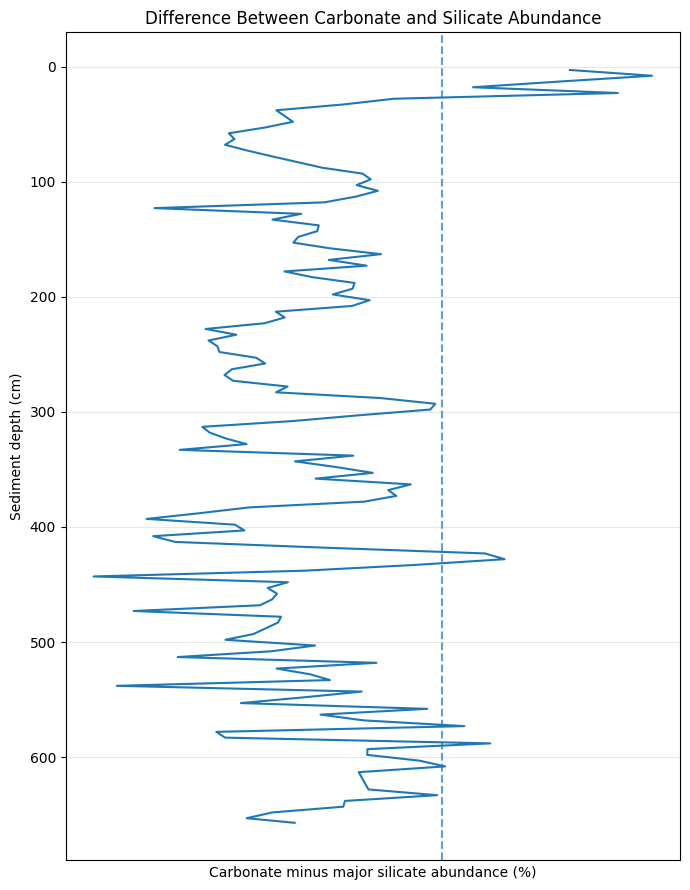

In [36]:
df["Carbonate_Silicate_Difference"] = (
    df["Reported_Carbonate_Sum_pct"]
    - df["Major_Silicate_Sum_pct"]
)

fig, ax = plt.subplots(figsize=(7, 9))

ax.plot(
    df["Carbonate_Silicate_Difference"],
    df["Depth_cm"],
    linewidth=1.5
)

ax.axvline(0, linestyle="--", alpha=0.7)

ax.invert_yaxis()

ax.set_xlabel("Carbonate minus major silicate abundance (%)")
ax.set_ylabel("Sediment depth (cm)")
ax.set_title("Difference Between Carbonate and Silicate Abundance")

ax.set_xticks([])

ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
silicate_columns = [
    "Quartz_pct",
    "Plagioclase_pct",
    "K_Feldspar_pct",
    "Phyllosilicate_pct"
]

silicate_data = df[["Depth_cm"] + silicate_columns].copy()

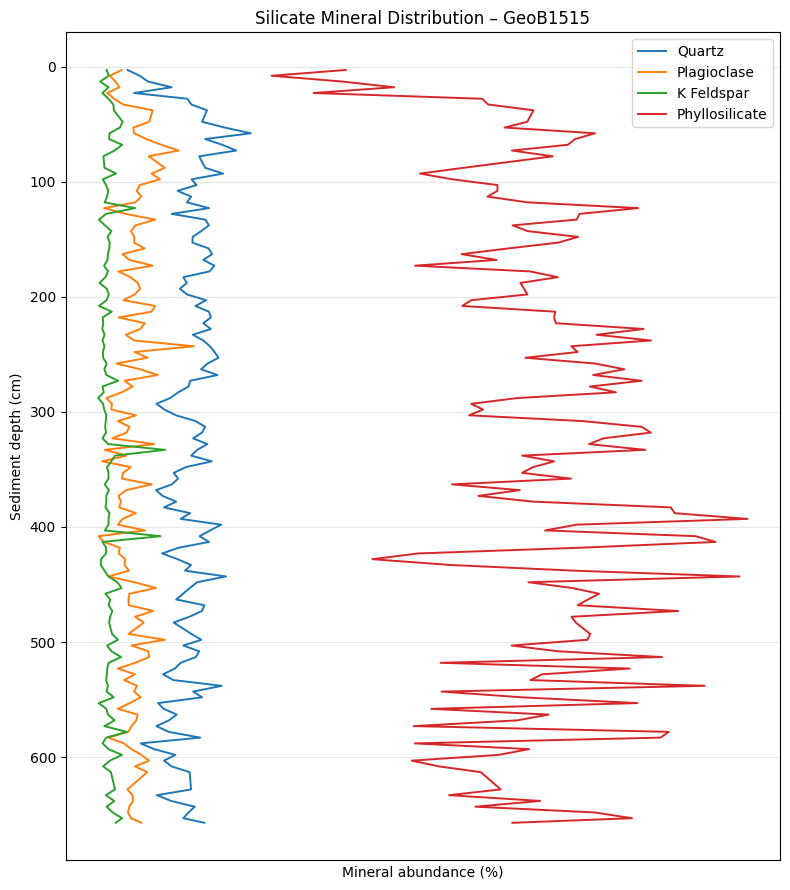

In [39]:
fig, ax = plt.subplots(figsize=(8, 9))

for mineral in silicate_columns:
    ax.plot(
        df[mineral],
        df["Depth_cm"],
        label=mineral.replace("_pct", "").replace("_", " "),
        linewidth=1.4
    )

ax.invert_yaxis()

ax.set_xlabel("Mineral abundance (%)")
ax.set_ylabel("Sediment depth (cm)")
ax.set_title("Silicate Mineral Distribution – GeoB1515")

ax.legend()
ax.grid(True, alpha=0.3)

ax.set_xticks([])

plt.tight_layout()
plt.show()

In [40]:
silicate_correlations = df[
    silicate_columns + ["Major_Silicate_Sum_pct"]
].corr()["Major_Silicate_Sum_pct"].drop(
    "Major_Silicate_Sum_pct"
).sort_values(ascending=False)

silicate_correlations

Phyllosilicate_pct    0.953742
Quartz_pct            0.642466
K_Feldspar_pct        0.334491
Plagioclase_pct       0.177299
Name: Major_Silicate_Sum_pct, dtype: float64

## Dolomite/Ankerite & Siderite/Magnesite

In [41]:
# Identify samples with measurable dolomite/ankerite
dolomanker_samples = carbonate_data[
    carbonate_data["Ankerite_Dolomite_pct"] > 0
][[
    "Sample_ID",
    "Depth_cm",
    "Ankerite_Dolomite_pct",
    "Siderite_Magnesite_pct"
]]

In [42]:
# Identify samples with measurable siderite/magnesite
sidermagnes_samples = carbonate_data[
    carbonate_data["Siderite_Magnesite_pct"] > 0
][[
    "Sample_ID",
    "Depth_cm",
    "Ankerite_Dolomite_pct",
    "Siderite_Magnesite_pct"
]]

In [43]:
keywords = ["pyrite", "iron", "fe", "magnetite",
            "chlorite", "illite", "smectite"]

related_columns = [
    col for col in df.columns
    if any(word in col.lower() for word in keywords)
]

In [44]:
columns_to_check = [
    "Depth_cm",
    "Calcite_pct",
    "Aragonite_pct",
    "Ankerite_Dolomite_pct",
    "Siderite_Magnesite_pct",
    "Pyrite_pct",
    "Magnetite_pct",
    "Iron_Oxides_Hydroxides_pct",
    "Illite_Mica_pct",
    "Kaolinite_pct",
    "Chlorite_pct"
]

intervals = pd.concat([
    df[df["Depth_cm"].between(183, 223)],
    df[df["Depth_cm"].between(443, 483)]
]).sort_values("Depth_cm")

In [45]:
variables = [
    "Siderite_Magnesite_pct",
    "Pyrite_pct",
    "Magnetite_pct",
    "Iron_Oxides_Hydroxides_pct",
    "Illite_Mica_pct",
    "Kaolinite_pct",
    "Chlorite_pct"
]

In [46]:
carbonate_relationships = [
    "Siderite_Magnesite_pct",
    "Calcite_pct",
    "Aragonite_pct",
    "Ankerite_Dolomite_pct",
    "Reported_Carbonate_Sum_pct"
]

In [47]:
df["Calcite_carbonate_pct"] = (
    df["Calcite_pct"] / df["Reported_Carbonate_Sum_pct"] * 100
)

df["Aragonite_carbonate_pct"] = (
    df["Aragonite_pct"] / df["Reported_Carbonate_Sum_pct"] * 100
)

## Aragonite Analysis

In [48]:
comparison = df[
    df["Depth_cm"].between(3, 23) |
    df["Depth_cm"].between(413, 428)
][[
    "Depth_cm",
    "Calcite_pct",
    "Aragonite_pct",
    "Ankerite_Dolomite_pct",
    "Siderite_Magnesite_pct",
    "Reported_Carbonate_Sum_pct",
    "Calcite_carbonate_pct",
    "Aragonite_carbonate_pct"
]].sort_values("Depth_cm")

In [49]:
comparison["Major_Silicate_Sum_pct"] = (
    comparison["Depth_cm"].map(
        df.set_index("Depth_cm")["Major_Silicate_Sum_pct"]
    )
)

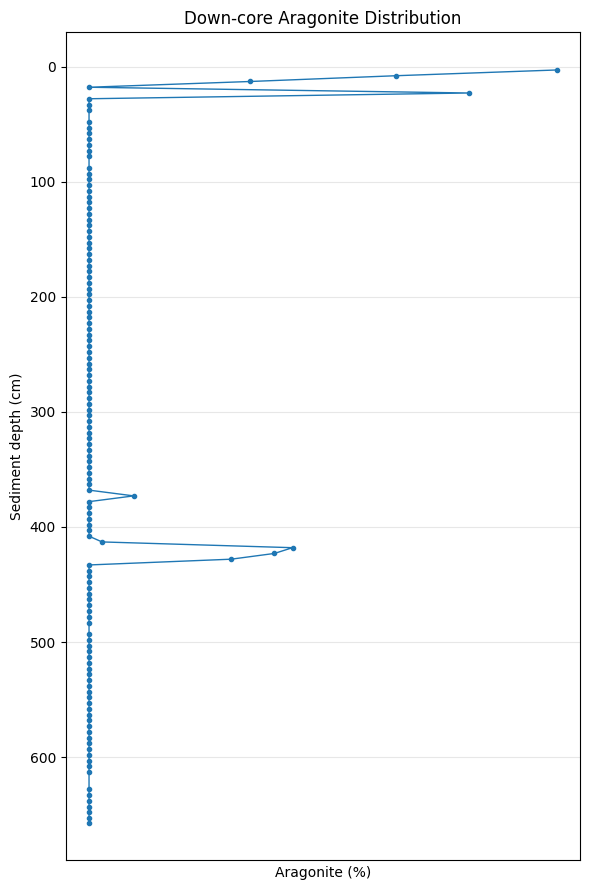

In [51]:
fig, ax = plt.subplots(figsize=(6, 9))

ax.plot(
    df["Aragonite_pct"],
    df["Depth_cm"],
    marker="o",
    markersize=3,
    linewidth=1
)

ax.set_xlabel("Aragonite (%)")
ax.set_ylabel("Sediment depth (cm)")
ax.set_title("Down-core Aragonite Distribution")

ax.invert_yaxis()
ax.grid(True, alpha=0.3)

ax.set_xticks([])

plt.tight_layout()
plt.show()

In [52]:
carbonate_normalized = [
    "Calcite_carbonate_pct",
    "Aragonite_carbonate_pct"
]

correlation_normalized = df[carbonate_normalized].corr(method="pearson")

print(correlation_normalized.round(3))

                         Calcite_carbonate_pct  Aragonite_carbonate_pct
Calcite_carbonate_pct                    1.000                   -0.856
Aragonite_carbonate_pct                 -0.856                    1.000


In [53]:
correlation_aragonite_total = df[
    ["Aragonite_carbonate_pct", "Reported_Carbonate_Sum_pct"]
].corr(method="pearson")

print(correlation_aragonite_total.round(3))

                            Aragonite_carbonate_pct  \
Aragonite_carbonate_pct                       1.000   
Reported_Carbonate_Sum_pct                    0.523   

                            Reported_Carbonate_Sum_pct  
Aragonite_carbonate_pct                          0.523  
Reported_Carbonate_Sum_pct                       1.000  


In [54]:
minor_carbonates = [
    "Depth_cm",
    "Aragonite_pct",
    "Mg_rich_Calcite_pct",
    "Ankerite_Dolomite_pct",
    "Siderite_Magnesite_pct"
]

aragonite_depths = df[df["Aragonite_pct"] > 0][minor_carbonates]

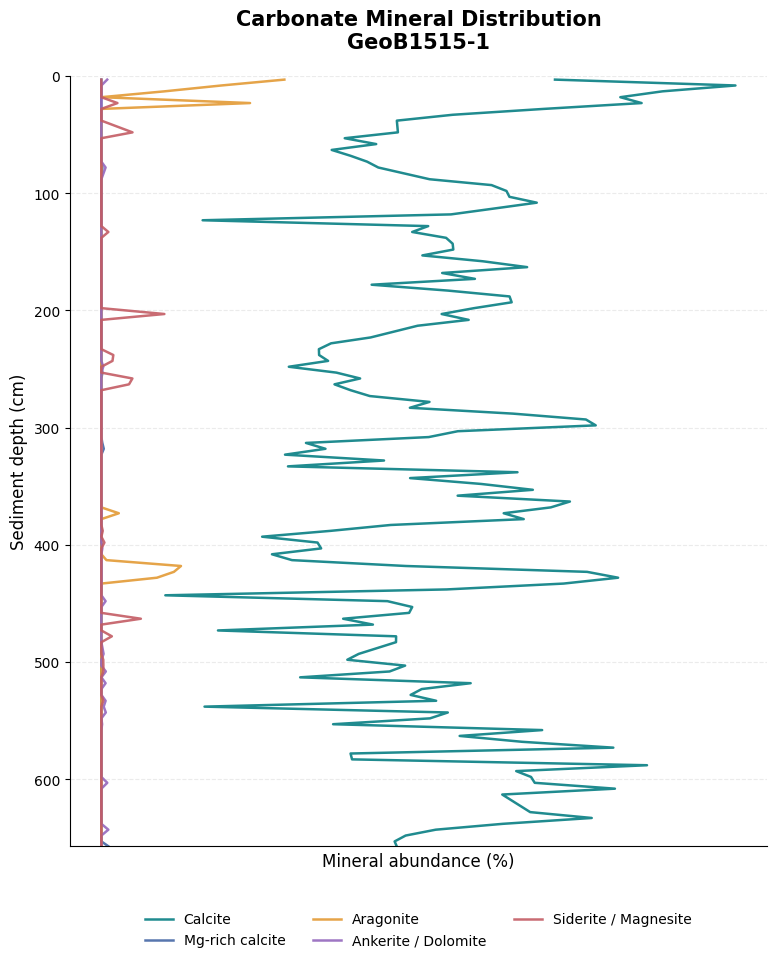

Figure saved to: /Users/jerry/carbonate_depth_profile.png


In [55]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# --------------------------------------------------
# 1. Load the XRD dataset
# --------------------------------------------------

# Change this path to your PRIVATE local Excel file.
# Do not upload the source dataset to your public repo.
file_path = "GeoB1515_XRD.xlsx"

df = pd.read_excel(file_path)

# --------------------------------------------------
# 2. Select carbonate minerals
# --------------------------------------------------

minerals = {
    "Calcite_pct": "Calcite",
    "Mg_rich_Calcite_pct": "Mg-rich calcite",
    "Aragonite_pct": "Aragonite",
    "Ankerite_Dolomite_pct": "Ankerite / Dolomite",
    "Siderite_Magnesite_pct": "Siderite / Magnesite",
}

required = ["Depth_cm", *minerals.keys()]

missing = [col for col in required if col not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

df = df[required].copy()
df = df.sort_values("Depth_cm")

# --------------------------------------------------
# 3. Configure the figure
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 10))

colors = {
    "Calcite_pct": "#087f83",
    "Mg_rich_Calcite_pct": "#4567a5",
    "Aragonite_pct": "#e39a35",
    "Ankerite_Dolomite_pct": "#9467bd",
    "Siderite_Magnesite_pct": "#c35c64",
}

# --------------------------------------------------
# 4. Plot mineral abundance against depth
# --------------------------------------------------

for column, label in minerals.items():
    ax.plot(
        df[column],
        df["Depth_cm"],
        label=label,
        color=colors[column],
        linewidth=1.8,
        alpha=0.9
    )

# --------------------------------------------------
# 5. Format the axes
# --------------------------------------------------

ax.invert_yaxis()

ax.set_xlabel(
    "Mineral abundance (%)",
    fontsize=12
)

ax.set_ylabel(
    "Sediment depth (cm)",
    fontsize=12
)

# Hide numerical abundance ticks, but retain depth ticks.
ax.set_xticks([])

# Keep the full core depth visible.
ax.set_ylim(df["Depth_cm"].max(), 0)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# --------------------------------------------------
# 6. Legend and title
# --------------------------------------------------

ax.set_title(
    "Carbonate Mineral Distribution\nGeoB1515-1",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.07),
    ncol=3,
    frameon=False,
    fontsize=10
)

# --------------------------------------------------
# 7. Export as a static PNG
# --------------------------------------------------

output_path = Path("carbonate_depth_profile.png")

fig.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Figure saved to: {output_path.resolve()}")
